In [1]:
!pip install -q medmnist plotly umap-learn

import os, hashlib, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import cv2
import medmnist
from medmnist import BloodMNIST, INFO
warnings.filterwarnings("ignore")

SIZE = 64
SEED = 42
np.random.seed(SEED)
os.makedirs("figures", exist_ok=True)
print("medmnist version:", medmnist.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 4.0 MB/s eta 0:00:00
medmnist version: 3.0.2


In [2]:
#Dataset load
info = INFO["bloodmnist"]
class_names = {int(k): v for k, v in info["label"].items()}
class_names[3] = "immature granulocytes"   # short name so plots stay readable
print(info["description"])
print("Task:", info["task"], "| Channels:", info["n_channels"], "| Classes:", len(class_names))
print(class_names)

splits = {}
for s in ["train", "val", "test"]:
    ds = BloodMNIST(split=s, download=True, size=SIZE)
    splits[s] = (ds.imgs, ds.labels.ravel())
    print(s, ds.imgs.shape, ds.imgs.dtype)

X_all = np.concatenate([splits[s][0] for s in splits])
y_all = np.concatenate([splits[s][1] for s in splits])
split_all = np.concatenate([[s]*len(splits[s][1]) for s in splits])
print("Total:", X_all.shape)

The BloodMNIST is based on a dataset of individual normal cells, captured from individuals without infection, hematologic or oncologic disease and free of any pharmacologic treatment at the moment of blood collection. It contains a total of 17,092 images and is organized into 8 classes. We split the source dataset with a ratio of 7:1:2 into training, validation and test set. The source images with resolution 3×360×363 pixels are center-cropped into 3×200×200, and then resized into 3×28×28.
Task: multi-class | Channels: 3 | Classes: 8
{0: 'basophil', 1: 'eosinophil', 2: 'erythroblast', 3: 'immature granulocytes', 4: 'lymphocyte', 5: 'monocyte', 6: 'neutrophil', 7: 'platelet'}


100%|██████████| 156M/156M [10:42<00:00, 243kB/s]


train (11959, 64, 64, 3) uint8
val (1712, 64, 64, 3) uint8
test (3421, 64, 64, 3) uint8
Total: (17092, 64, 64, 3)


In [3]:
#Summary table(A)
summary = pd.DataFrame({
    "Item": ["Dataset", "Source", "Area", "Total images", "Train/Val/Test",
             "Classes", "Format", "Resolution", "Channels", "Problem type"],
    "Value": ["BloodMNIST (MedMNIST v2)",
              "Acevedo et al. 2020, blood cell microscope images (via medmnist.com)",
              "Medical imaging / hematology",
              len(X_all),
              f"{len(splits['train'][1])} / {len(splits['val'][1])} / {len(splits['test'][1])}",
              len(class_names), "uint8 NumPy arrays (.npz)", f"{SIZE}x{SIZE}",
              "3 (RGB)", "Multi-class classification (8 classes)"]
})
display(summary)
summary.to_csv("figures/A_summary.csv", index=False)


,Item,Value
0,Dataset,BloodMNIST (MedMNIST v2)
1,Source,"Acevedo et al. 2020, blood cell microscope ima..."
2,Area,Medical imaging / hematology
3,Total images,17092
4,Train/Val/Test,11959 / 1712 / 3421
5,Classes,8
6,Format,uint8 NumPy arrays (.npz)
7,Resolution,64x64
8,Channels,3 (RGB)
9,Problem type,Multi-class classification (8 classes)


split,train,val,test,total
class,,,,
neutrophil,2330,333,666,3329
eosinophil,2181,312,624,3117
immature granulocytes,2026,290,579,2895
platelet,1643,235,470,2348
erythroblast,1085,155,311,1551
monocyte,993,143,284,1420
basophil,852,122,244,1218
lymphocyte,849,122,243,1214


Majority: neutrophil (3329) | Minority: lymphocyte (1214)
Majority-to-minority ratio: 2.74


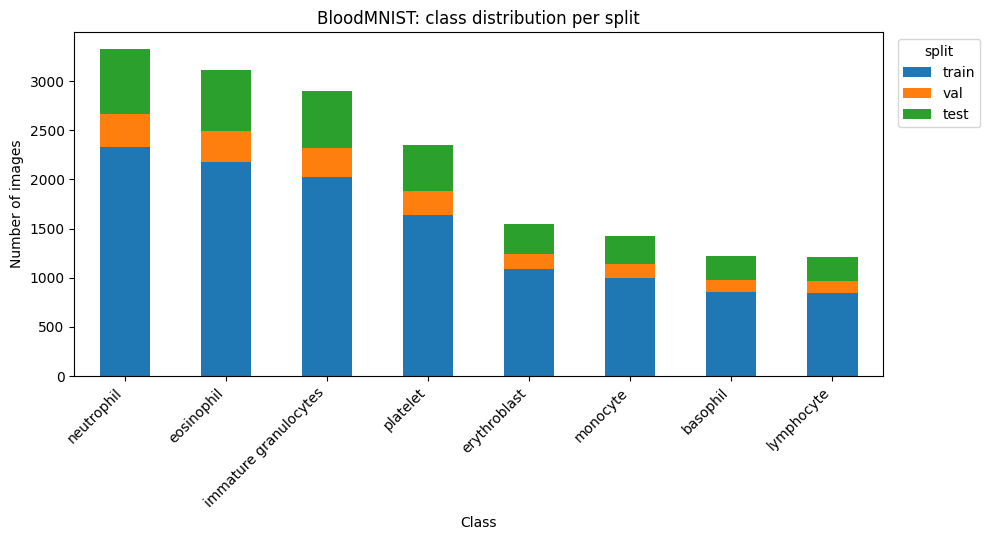

In [4]:
#Class balance (B)
df = pd.DataFrame({"label": y_all, "split": split_all})
df["class"] = df["label"].map(class_names)

counts = df.groupby(["class", "split"]).size().unstack(fill_value=0)
counts = counts[["train", "val", "test"]]
counts["total"] = counts.sum(axis=1)
counts = counts.sort_values("total", ascending=False)
display(counts)

maj, mino = counts["total"].max(), counts["total"].min()
print(f"Majority: {counts['total'].idxmax()} ({maj}) | Minority: {counts['total'].idxmin()} ({mino})")
print(f"Majority-to-minority ratio: {maj/mino:.2f}")

ax = counts[["train","val","test"]].plot(kind="bar", stacked=True, figsize=(10,5.5))
ax.set_title("BloodMNIST: class distribution per split")
ax.set_xlabel("Class"); ax.set_ylabel("Number of images")
ax.legend(title="split", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
plt.savefig("figures/B_class_balance.png", dpi=200, bbox_inches="tight"); plt.show()

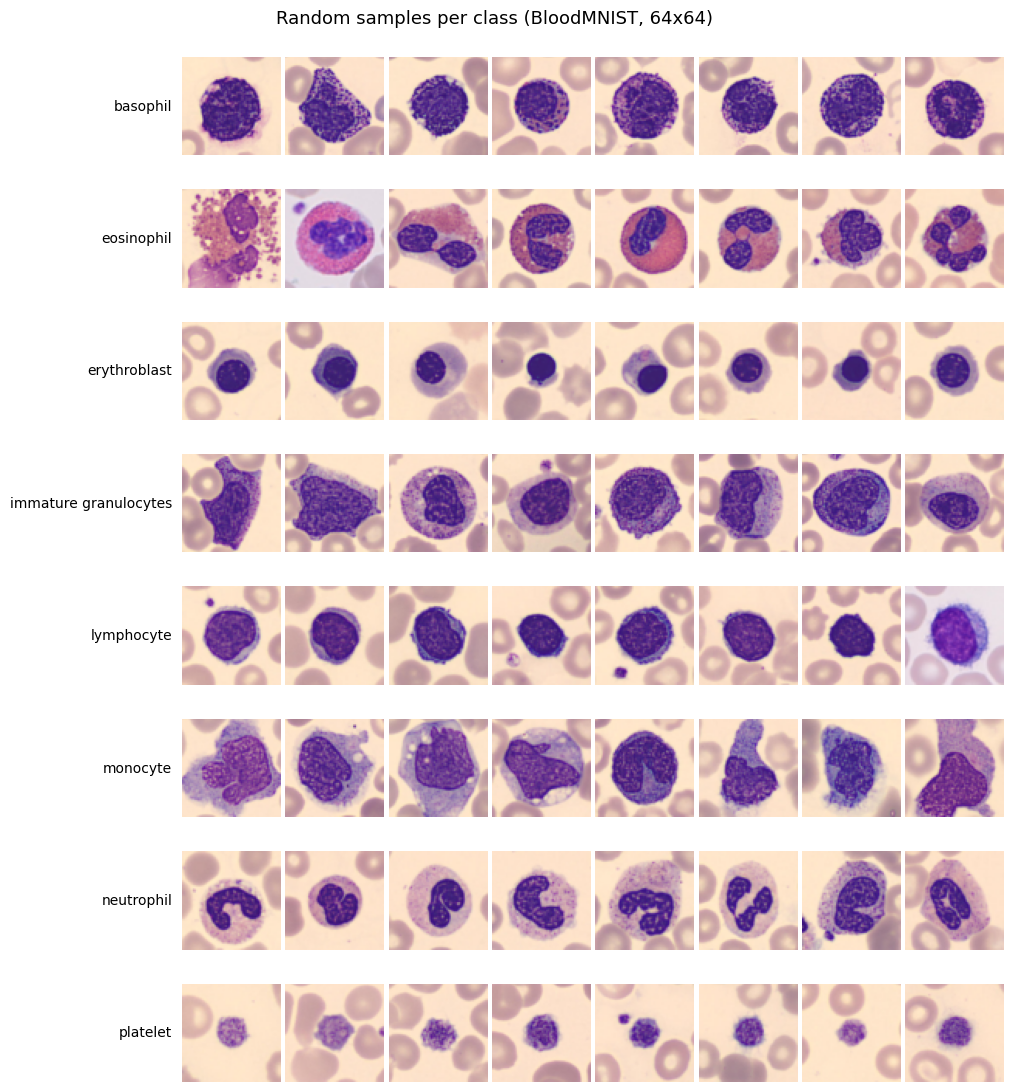

In [5]:
#(C) Labelled sample grid
n_per_class = 8
fig, axes = plt.subplots(len(class_names), n_per_class,
                         figsize=(n_per_class*1.3, len(class_names)*1.4))
for c in range(len(class_names)):
    idx = np.where(y_all == c)[0]
    pick = np.random.choice(idx, n_per_class, replace=False)
    for j, i in enumerate(pick):
        axes[c, j].imshow(X_all[i]); axes[c, j].axis("off")
    axes[c, 0].text(-0.1, 0.5, class_names[c], transform=axes[c, 0].transAxes,
                    ha="right", va="center", fontsize=10)
fig.suptitle("Random samples per class (BloodMNIST, 64x64)", fontsize=13)
plt.subplots_adjust(left=0.2, right=0.99, top=0.95, bottom=0.01, wspace=0.05, hspace=0.05)
plt.savefig("figures/C_sample_grid.png", dpi=200, bbox_inches="tight"); plt.show()

In [6]:
#(D) Size / resolution
print("Array shape per image:", X_all.shape[1:], "| dtype:", X_all.dtype)
print("Unique shapes:", {X_all.shape[1:]})
print(f"Memory (uint8): {X_all.nbytes/1e6:.1f} MB")
print("Pixel value range:", X_all.min(), "-", X_all.max())

res = pd.DataFrame({
    "MedMNIST size": [28, 64, 128, 224],
    "Pixels/image": [28*28, 64*64, 128*128, 224*224],
    "Approx. MB (17092 imgs, RGB)": [round(17092*s*s*3/1e6, 1) for s in [28,64,128,224]]
})
display(res)

Array shape per image: (64, 64, 3) | dtype: uint8
Unique shapes: {(64, 64, 3)}
Memory (uint8): 210.0 MB
Pixel value range: 8 - 255


,MedMNIST size,Pixels/image,"Approx. MB (17092 imgs, RGB)"
0,28,784,40.2
1,64,4096,210.0
2,128,16384,840.1
3,224,50176,2572.8


Mean RGB: [0.796  0.6596 0.6963]
Std  RGB: [0.2232 0.2546 0.0947]


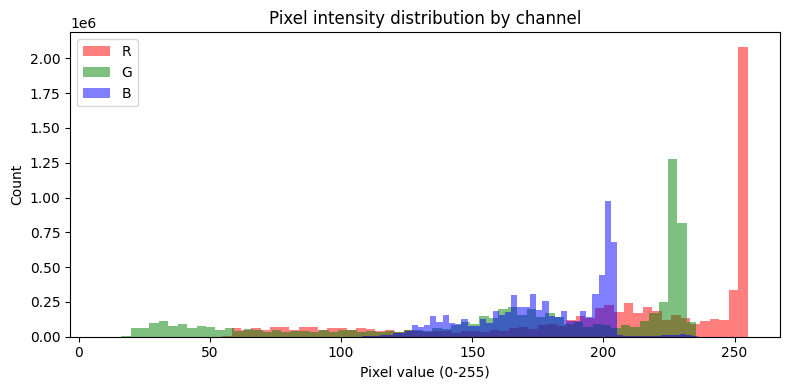

,class,R,G,B
0,basophil,0.7559,0.6136,0.6815
1,eosinophil,0.7877,0.6317,0.6799
2,erythroblast,0.8329,0.7149,0.7133
3,immature granulocytes,0.7441,0.6077,0.6860
4,lymphocyte,0.8052,0.6791,0.7002
5,monocyte,0.7285,0.5916,0.6876
6,neutrophil,0.8012,0.6650,0.6976
7,platelet,0.8962,0.7710,0.7289


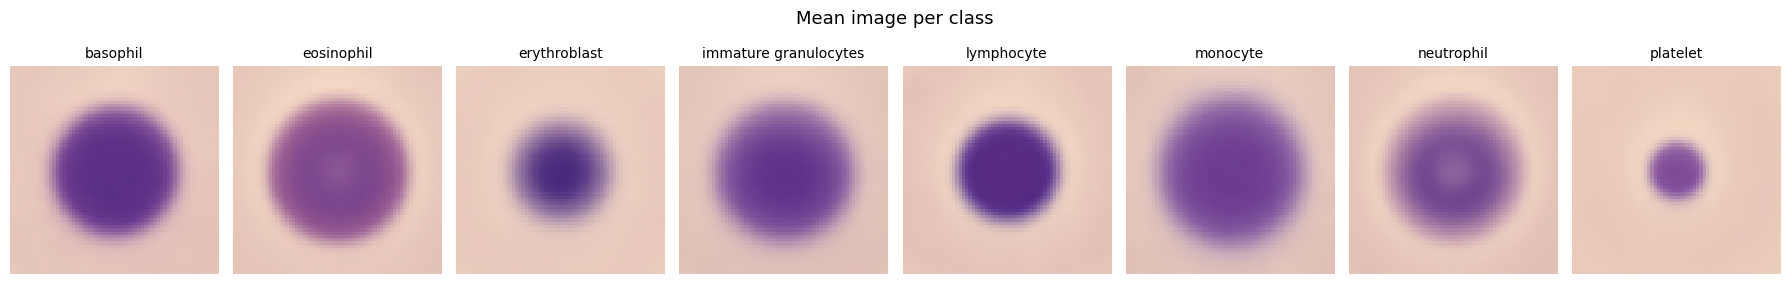

In [7]:
#(E) Pixel / colour analysis
# Overall channel mean/std (float64 to avoid float32 precision errors)
Xf = X_all.astype(np.float32) / 255.0
mean_rgb = X_all.mean(axis=(0,1,2), dtype=np.float64) / 255.0
std_rgb  = X_all.astype(np.float64).std(axis=(0,1,2)) / 255.0
print("Mean RGB:", mean_rgb.round(4))
print("Std  RGB:", std_rgb.round(4))

# Channel histograms
plt.figure(figsize=(8,4))
for i, (ch, col) in enumerate(zip("RGB", ["red","green","blue"])):
    plt.hist(X_all[::10, :, :, i].ravel(), bins=64, alpha=0.5, color=col, label=ch)
plt.title("Pixel intensity distribution by channel")
plt.xlabel("Pixel value (0-255)"); plt.ylabel("Count"); plt.legend()
plt.tight_layout(); plt.savefig("figures/E_channel_hist.png", dpi=200); plt.show()

# Per-class mean colour
rows = []
for c in range(len(class_names)):
    m = X_all[y_all == c].mean(axis=(0,1,2), dtype=np.float64) / 255.0
    rows.append({"class": class_names[c], "R": m[0], "G": m[1], "B": m[2]})
colour_df = pd.DataFrame(rows).round(4)
display(colour_df)
colour_df.to_csv("figures/E_class_colour.csv", index=False)

# Mean image per class
fig, axes = plt.subplots(1, len(class_names), figsize=(18, 3))
for c in range(len(class_names)):
    axes[c].imshow(Xf[y_all == c].mean(axis=0, dtype=np.float64)); axes[c].axis("off")
    axes[c].set_title(class_names[c], fontsize=10)
plt.suptitle("Mean image per class", fontsize=13); plt.tight_layout()
plt.savefig("figures/E_mean_images.png", dpi=200); plt.show()

,brightness,contrast,sharpness
class,,,
basophil,169.32,64.44,1319.94
eosinophil,174.40,58.60,913.86
erythroblast,191.29,52.36,398.43
immature granulocytes,167.65,60.70,1069.73
lymphocyte,183.43,59.35,559.62
monocyte,164.09,58.05,1044.16
neutrophil,180.92,54.59,800.48
platelet,204.95,32.94,219.75


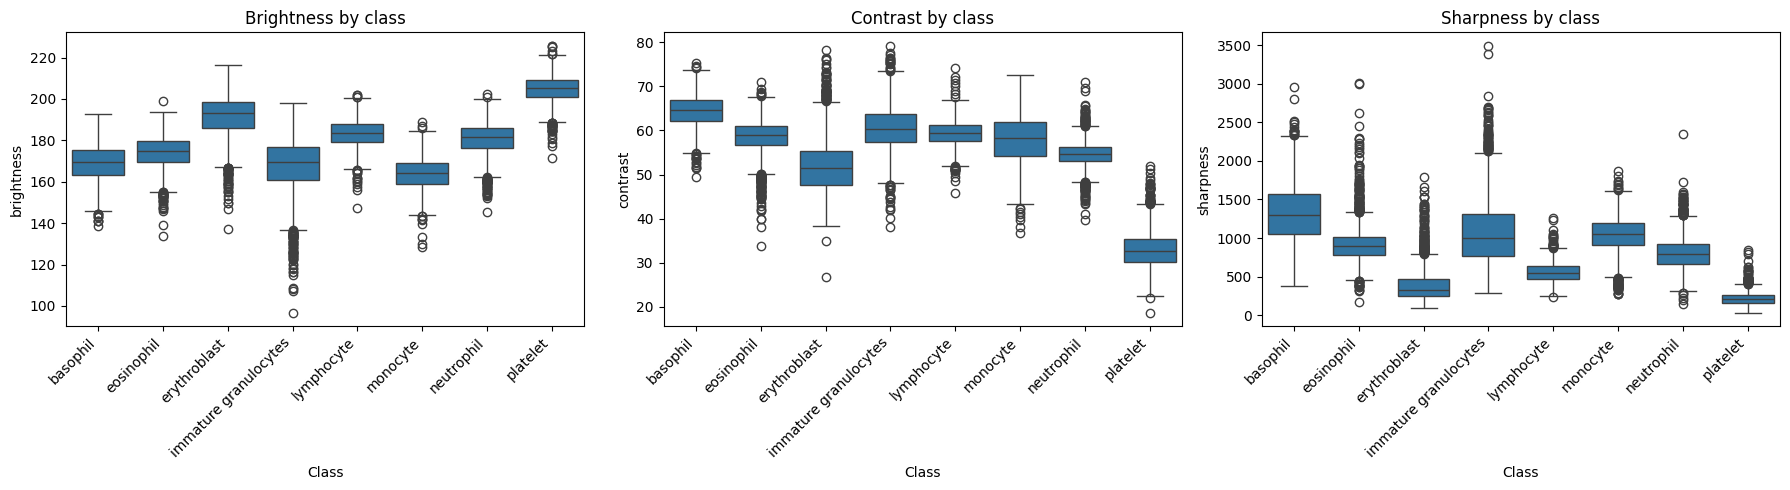

Exact duplicate images: 17
Duplicates shared across splits (leakage risk): 9
Same image with different labels: 1
Very dark images (mean<20): 0


In [8]:
#(F) Image quality (blur, brightness, contrast, duplicates)
gray = np.array([cv2.cvtColor(im, cv2.COLOR_RGB2GRAY) for im in X_all])
quality = pd.DataFrame({
    "class": [class_names[l] for l in y_all],
    "split": split_all,
    "brightness": gray.reshape(len(gray), -1).mean(axis=1),
    "contrast": gray.reshape(len(gray), -1).std(axis=1),
    "sharpness": [cv2.Laplacian(g, cv2.CV_64F).var() for g in gray],
})
q_table = quality.groupby("class")[["brightness","contrast","sharpness"]].mean().round(2)
display(q_table)
q_table.to_csv("figures/F_quality_table.csv")

order = list(class_names.values())
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ["brightness","contrast","sharpness"]):
    sns.boxplot(data=quality, x="class", y=col, order=order, ax=ax)
    ax.set_title(f"{col.capitalize()} by class"); ax.set_xlabel("Class")
    ax.tick_params(axis="x", rotation=45)
    plt.setp(ax.get_xticklabels(), ha="right")
plt.tight_layout(); plt.savefig("figures/F_quality.png", dpi=200); plt.show()

# Exact duplicate check (important for leakage!)
hashes = np.array([hashlib.md5(im.tobytes()).hexdigest() for im in X_all])
dup_df = pd.DataFrame({"hash": hashes, "split": split_all, "label": y_all})
n_dup = len(hashes) - len(set(hashes))
print("Exact duplicate images:", n_dup)

g = dup_df.groupby("hash")["split"].nunique()
print("Duplicates shared across splits (leakage risk):", int((g > 1).sum()))
g2 = dup_df.groupby("hash")["label"].nunique()
print("Same image with different labels:", int((g2 > 1).sum()))

# Near-black / near-blank images
print("Very dark images (mean<20):", int((quality.brightness < 20).sum()))

In [9]:
#(G) Interactive plots (Plotly)
order = list(class_names.values())
palette = px.colors.qualitative.Plotly
color_map = {n: palette[i] for i, n in enumerate(order)}   # same colour for a class in every chart

# 1. Interactive class counts
cc = df["class"].value_counts().reindex(order).reset_index()
cc.columns = ["class", "count"]
fig = px.bar(cc, x="class", y="count", color="class", color_discrete_map=color_map,
             title="BloodMNIST class counts", width=900, height=450)
fig.update_layout(showlegend=False, xaxis_tickangle=-30)
fig.write_html("figures/G_class_counts.html", include_plotlyjs="cdn")
fig.show()

def scatter2d(d, x, y, title, fname, hover=None):
    fig = px.scatter(d, x=x, y=y, color="class", color_discrete_map=color_map,
                     category_orders={"class": order}, hover_data=hover,
                     opacity=0.6, title=title, width=950, height=550)
    fig.update_traces(marker=dict(size=5))
    fig.write_html(f"figures/{fname}.html", include_plotlyjs="cdn")
    fig.show()

# 2. Interactive quality scatter
samp = quality.sample(3000, random_state=SEED)
scatter2d(samp, "brightness", "sharpness", "Brightness vs sharpness per image",
          "G_brightness_sharpness", hover=["contrast","split"])

# 3. PCA 2D view (pixel space)
from sklearn.decomposition import PCA
idx = np.random.choice(len(X_all), 4000, replace=False)
flat = Xf[idx].reshape(len(idx), -1)
pca = PCA(n_components=2, random_state=SEED).fit_transform(flat)
pdf = pd.DataFrame({"PC1": pca[:,0], "PC2": pca[:,1],
                    "class": [class_names[l] for l in y_all[idx]]})
scatter2d(pdf, "PC1", "PC2", "PCA of raw pixels", "G_pca")

# 4. UMAP
import umap
emb = umap.UMAP(n_components=2, random_state=SEED).fit_transform(flat)
udf = pd.DataFrame({"UMAP1": emb[:,0], "UMAP2": emb[:,1], "class": pdf["class"]})
scatter2d(udf, "UMAP1", "UMAP2", "UMAP of raw pixels", "G_umap")

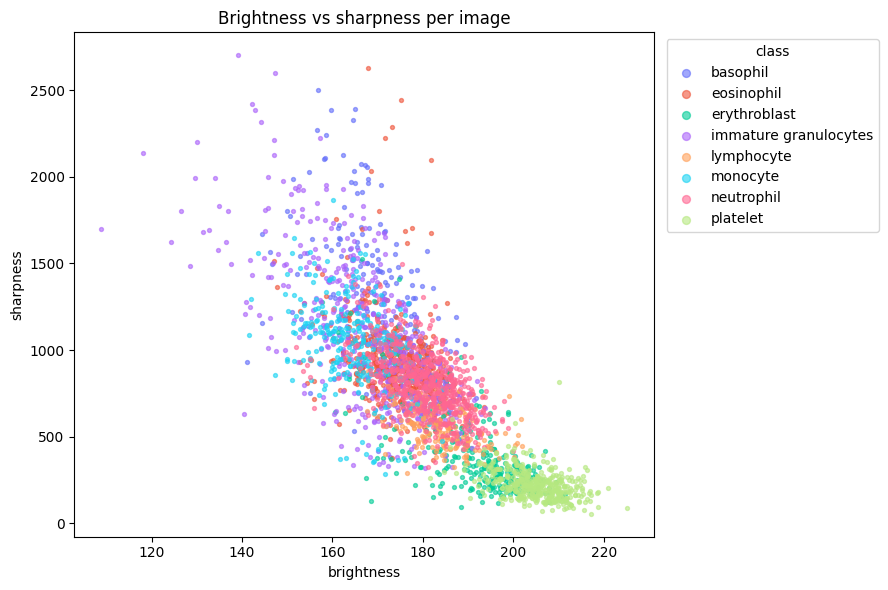

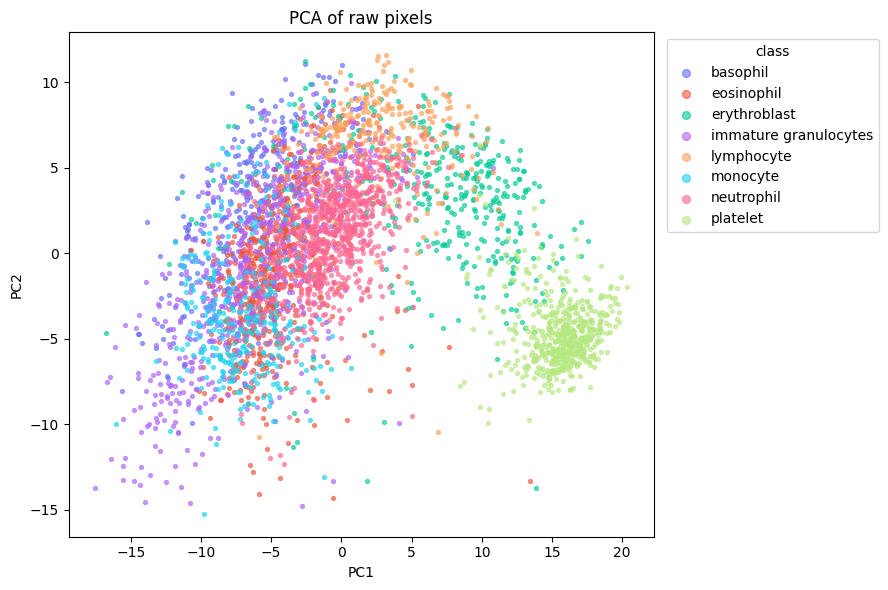

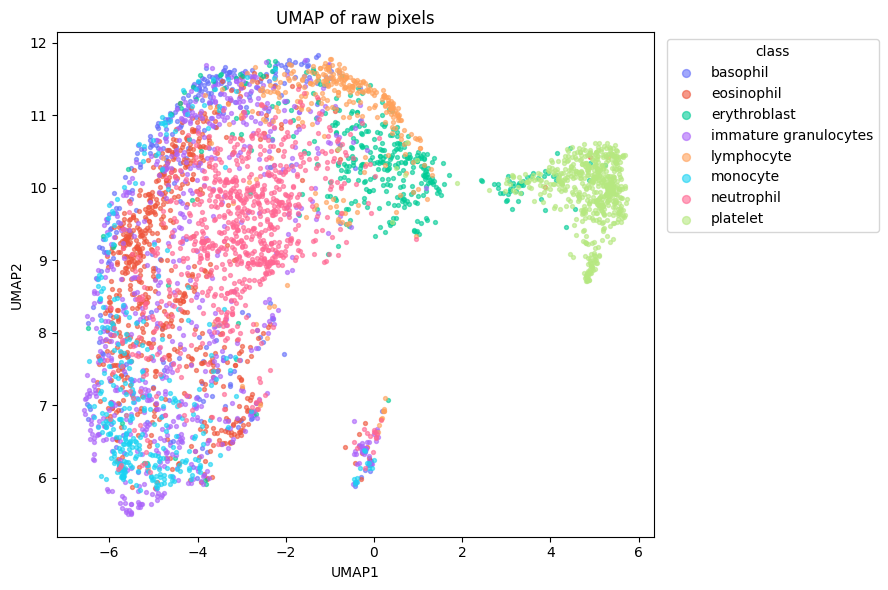

In [10]:
#(G2) Static copies of the interactive plots 
def static_scatter(d, x, y, title, fname):
    fig, ax = plt.subplots(figsize=(9, 6))
    for n in order:
        s = d[d["class"] == n]
        ax.scatter(s[x], s[y], s=8, alpha=0.6, color=color_map[n], label=n)
    ax.set_title(title); ax.set_xlabel(x); ax.set_ylabel(y)
    ax.legend(title="class", markerscale=2, loc="upper left", bbox_to_anchor=(1.01, 1))
    plt.tight_layout()
    plt.savefig(f"figures/{fname}.png", dpi=200, bbox_inches="tight"); plt.show()

static_scatter(samp, "brightness", "sharpness", "Brightness vs sharpness per image", "G_brightness_sharpness")
static_scatter(pdf, "PC1", "PC2", "PCA of raw pixels", "G_pca")
static_scatter(udf, "UMAP1", "UMAP2", "UMAP of raw pixels", "G_umap")

In [11]:
#save dataset for task 2
np.savez_compressed(f"bloodmnist_{SIZE}_all.npz", X=X_all, y=y_all, split=split_all)
print("Saved.")
!zip -qr figures.zip figures

Saved.
